In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()
df_test = off_market.copy()

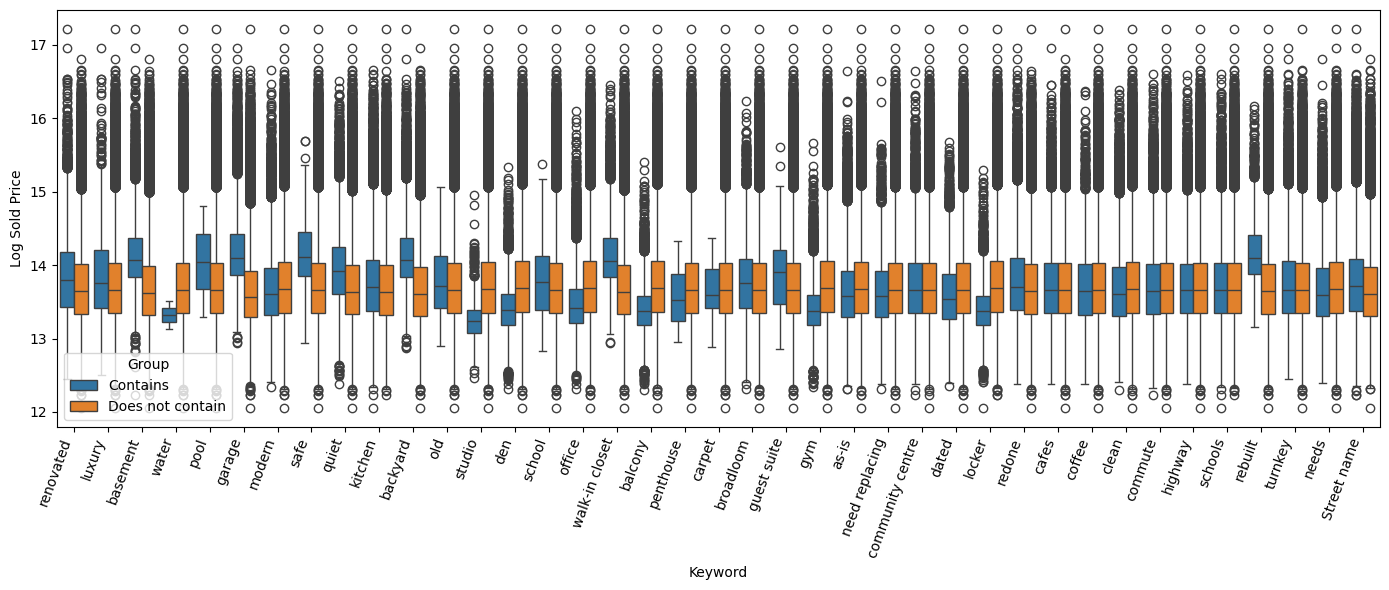

In [3]:
keywords = [
    "renovated", "luxury", "basement", "water",
    "pool", "garage", "modern", "safe", "quiet",
    "kitchen", "backyard", "old", "studio", "den",
    "school", "office", "walk-in closet", "balcony",
    "penthouse", "carpet", "broadloom", "guest suite",
    "gym", "as-is", "need replacing", "community centre",
    "dated", "locker", "redone", "cafes", "coffee", "clean",
    "commute", "highway", "schools", "rebuilt", "turnkey", "needs"
]

df["log_sold_price"] = np.log(df["sold_price"])

plot_data = []
for word in keywords:
    mask = df["remarks"].str.contains(r"\b" + word + r"\b", case=False, na=False, regex=True)
    plot_data.extend([
        {"Keyword": word, "Group": "Contains", "Price": p}
        for p in df.loc[mask, "log_sold_price"]
    ])
    plot_data.extend([
        {"Keyword": word, "Group": "Does not contain", "Price": p}
        for p in df.loc[~mask, "log_sold_price"]
    ])
street_names_pattern = r"\b(?:way|boulevard|street|avenue|court|drive|road|place|trail|lane|plaza|gardens|crescent)\b"
mask = df["remarks"].str.contains(street_names_pattern, case=False, na=False, regex=True)
plot_data.extend([
    {"Keyword": "Street name", "Group": "Contains", "Price": p}
    for p in df.loc[mask, "log_sold_price"]
])
plot_data.extend([
    {"Keyword": "Street name", "Group": "Does not contain", "Price": p}
    for p in df.loc[~mask, "log_sold_price"]
])

plot_df = pd.DataFrame(plot_data)

plt.figure(figsize=(14, 6))
sns.boxplot(data=plot_df, x="Keyword", y="Price", hue="Group")
plt.xticks(rotation=70, ha="right")
plt.ylabel("Log Sold Price")
plt.tight_layout()
plt.show()

In [15]:
for i in range(20):
    rand_index = np.random.randint(0, len(df))
    print(f"House Index: {df.index[rand_index]}")
    print(f"Log Sold Price: {df['log_sold_price'].iloc[rand_index]}")
    print(f"Remarks: {df['remarks'].iloc[rand_index]}")
    print("\n")

House Index: 25533
Log Sold Price: 13.453823072201997
Remarks: Picture coming home to your cozy unit on Birch Court after a day out. This 1-bedroom condo has broadloom in the bedrooms and a functional layout. The bathrooms are older but clean and liveable. You'll have a concierge for convenience and one parking spot. Steps to shops, restaurants, and transit. A move-up buyer will appreciate the space and the building's amenities.


House Index: 125619
Log Sold Price: 14.407787128139246
Remarks: Sequoiafield offers this beautifully finished freehold townhouse on Spruce Boulevard, ready for a growing family. The open-concept main floor features a walk-out to the deck, perfect for summer barbecues. Custom closet organizers keep the 3 bedrooms neat. With 4 bathrooms and over 2,100 sq ft, there's room for everyone. Mature trees line the street, and schools and highway access are close. You can move right in and start making memories.


House Index: 7406
Log Sold Price: 13.613027109346367
Rem

In [44]:
df["remarks"] = df["remarks"].fillna("").str.lower()
communities = df["community"].str.lower().unique()
numbers = ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine", "ten"]

In [55]:
street_names_pattern = r"\b(?:way|boulevard|street|avenue|court|drive|road|place|trail|lane|plaza|gardens|crescent)\b"
has_street_name_count = df["remarks"].str.contains(street_names_pattern, case=False, na=False).sum()
print(f"Number of remarks containing street names: {has_street_name_count} out of {len(df)}")

Number of remarks containing street names: 73703 out of 150000


In [47]:
from sklearn.feature_extraction.text import TfidfVectorizer
import re

def clean(s):
    s = s.lower()
    s = re.sub(r"\d[\d,\.]*", " NUM ", s)
    communities_match = r"\b(?:" + "|".join(map(re.escape, communities)) + r")\b"
    numbers_word_match = r"\b(?:" + "|".join(map(re.escape, numbers)) + r")\b"
    s = re.sub(communities_match, " COMMUNITY ", s)
    s = re.sub(numbers_word_match, " NUM ", s)
    return s

tfidf = TfidfVectorizer(
    preprocessor=clean,
    ngram_range=(1, 3),     # unigrams, bigrams, trigrams
    min_df=10,              # drop terms in fewer than 10 remarks
    max_df=0.50,             # drop terms in more than half
    sublinear_tf=True,      # use 1 + log(tf) instead of raw tf
    stop_words=None,        # keep "no", "not", "as", "is" for negation and "as-is"
    max_features=50_000,
)
X_text = tfidf.fit_transform(df["remarks"])
X_text.shape

(150000, 50000)

In [48]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import KFold, cross_val_predict

ridge = Ridge(alpha=1.0)
kf = KFold(5, shuffle=True, random_state=0)
df["text_score"] = cross_val_predict(ridge, X_text, df["log_sold_price"], cv=kf)

ridge_mdape = np.median(np.abs(df["log_sold_price"] - df["text_score"]))
print(f"Ridge MDAPE: {ridge_mdape:.4f}")

Ridge MDAPE: 0.2013


In [ ]:
import numpy as np
names = np.array(tfidf.get_feature_names_out())
coef = ridge.fit(X_text, df["log_sold_price"]).coef_
print(names[np.argsort(coef)[-10:]])   # price-raising terms
print(names[np.argsort(coef)[:10]])    # price-lowering terms

['bath condo townhouse' 'huge' 'lot with about' 'cedar boulevard' 'across'
 'discerning buyer' 'cedar crescent' 'spans' 'bathroom detached'
 'NUM bathroom detached' 'detached at' 'bedroom on quiet' 'sycamore court'
 'on aspen avenue' 'sequoia gardens' 'incredible' 'balsam way'
 'on sumac road' 'balsam drive' 'everyone' 'birch street' 'NUM bath home'
 'bath home' 'grand NUM' 'remarkable' 'sidesplit' 'bathrooms'
 'COMMUNITY home' 'expansive NUM' 'oak avenue' 'entertain' 'birch gardens'
 'generous' 'NUM bathroom home' 'bathroom home' 'cedar drive'
 'rowan street' 'on birch street' 'home on' 'serious' 'garage'
 'mulberry lane' 'entertainers' 'oak lane' 'this impressive' 'luxury'
 'turnkey luxury' 'large family' 'ash way' 'sprawling' 'for large'
 'this large' 'this stunning home' 'fenced' 'cedar trail'
 'bathroom home on' 'rare NUM' 'house' 'impressive' 'residence on' 'large'
 'residence' 'sycamore gardens' 'NUM bedroom home' 'bedroom home'
 'magnolia gardens' 'juniper gardens' 'sumac road'

## Using Funny LLM To do the Work

In [5]:
# iterate through all remarks. Find the street name and add to column for street. No street name found, return "unknown"
import torch
from transformers import AutoModelForImageTextToText, AutoTokenizer, BitsAndBytesConfig
from accelerate import Accelerator
device = Accelerator().device

MODEL_ID = "Qwen/Qwen3.5-4B"

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_use_double_quant=True,
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, padding_side="left")
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForImageTextToText.from_pretrained(
    MODEL_ID,
    quantization_config=bnb_config,
    device_map="auto",
)
model.eval()

Loading weights: 100%|██████████| 723/723 [00:00<00:00, 818.92it/s]


Qwen3_5ForConditionalGeneration(
  (model): Qwen3_5Model(
    (visual): Qwen3_5VisionModel(
      (patch_embed): Qwen3_5VisionPatchEmbed(
        (proj): Conv3d(3, 1024, kernel_size=(2, 16, 16), stride=(2, 16, 16))
      )
      (pos_embed): Embedding(2304, 1024)
      (rotary_pos_emb): Qwen3_5VisionRotaryEmbedding()
      (blocks): ModuleList(
        (0-23): 24 x Qwen3_5VisionBlock(
          (norm1): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
          (norm2): LayerNorm((1024,), eps=1e-06, elementwise_affine=True, bias=True)
          (attn): Qwen3_5VisionAttention(
            (qkv): Linear4bit(in_features=1024, out_features=3072, bias=True)
            (proj): Linear4bit(in_features=1024, out_features=1024, bias=True)
          )
          (mlp): Qwen3_5VisionMLP(
            (linear_fc1): Linear4bit(in_features=1024, out_features=4096, bias=True)
            (linear_fc2): Linear4bit(in_features=4096, out_features=1024, bias=True)
            (act_fn): GELU

In [9]:
from tqdm.auto import tqdm

SYSTEM_PROMPT = (
    "You extract street names from real estate listing remarks. "
    "Reply with only the street name, e.g. 'spruce boulevard'. "
    "The street must have a street suffix like 'street', 'avenue', 'boulevard', etc. "
    "Generic phrases like 'quiet street' or 'tree-lined street' are not street names. "
    "If no specific street name is mentioned, reply 'unknown'."
    "Reply with the street name in lowercase, without any punctuation or extra words. "
)
BATCH_SIZE = 32


def build_prompt(remark):
    messages = [
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": remark},
    ]
    return tokenizer.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True, enable_thinking=False
    )


def parse_answer(text):
    answer = text.strip().splitlines()[0] if text.strip() else ""
    answer = answer.strip(" .'\"`").lower()
    return answer or "unknown"


@torch.inference_mode()
def extract_streets(remarks):
    prompts = [build_prompt(r) for r in remarks]
    inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
    outputs = model.generate(
        **inputs,
        max_new_tokens=16,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id,
    )
    new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
    return [parse_answer(t) for t in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]


remarks = df["remarks"].tolist()
streets = []
for start in tqdm(range(0, len(remarks), BATCH_SIZE)):
    batch = remarks[start:start + BATCH_SIZE]
    to_run = [r for r in batch if r.strip()]
    results = iter(extract_streets(to_run)) if to_run else iter([])
    streets.extend(next(results) if r.strip() else "unknown" for r in batch)

df["street_llm"] = streets
df["street_llm"].value_counts().head(20)

100%|██████████| 4688/4688 [4:02:09<00:00,  3.10s/it]  

['unknown', 'sequoia trail', 'unknown', 'magnolia lane', 'unknown', 'unknown', 'unknown', 'cypressdale', 'cypress gardens', 'unknown', 'unknown', 'unknown', 'unknown', 'unknown', 'juniperpark', 'unknown', 'hawthorn avenue', 'unknown', 'poplar way', 'unknown', 'unknown', 'ashworth', 'unknown', 'alder gardens', 'unknown', 'sequoia avenue', 'cedar boulevard', 'spruce road', 'unknown', 'unknown', 'unknown', 'unknown', 'tamarack place', 'hawthorn rd', 'unknown', 'unknown', 'unknown', 'sequoia court', 'unknown', 'unknown', 'unknown', 'hawthorn lane', 'sequoia crescent', 'cedar lane', 'hemlock road', 'unknown', 'unknown', 'sumac road', 'sumac way', 'willow avenue', 'unknown', 'chestnutbank', 'birch lane', 'unknown', 'unknown', 'unknown', 'unknown', 'pine lane', 'hazel gardens', 'unknown', 'unknown', 'ash trail', 'unknown', 'rowan court', 'unknown', 'unknown', 'unknown', 'rowan crescent', 'walnut lane', 'unknown', 'unknown', 'unknown', 'oak gardens', 'mulberrygrove', 'unknown', 'chestnutbourne

street_llm
unknown            73892
elmview              944
beechbourne          705
alder drive          586
spruceview           540
cedar boulevard      518
hemlock drive        516
hemlockvale          513
birch lane           496
beech road           490
sequoia court        489
larch street         483
sequoia way          474
hemlock court        474
cedar crescent       457
hickory place        446
juniper way          436
cypress drive        427
oak road             426
hawthorn lane        422
Name: count, dtype: int64

In [10]:
df.to_csv("remarks_with_streets.csv", index=False)

In [12]:
df["street_llm"] = df["street_llm"].fillna("unknown").str.lower()
df.loc[df["street_llm"].str.split().str.len() < 2, "street_llm"] = "unknown"

In [14]:
df["street_llm"].value_counts().head(20)

street_llm
unknown            89137
alder drive          586
cedar boulevard      518
hemlock drive        516
birch lane           496
beech road           490
sequoia court        489
larch street         483
hemlock court        474
sequoia way          474
cedar crescent       457
hickory place        446
juniper way          436
cypress drive        427
oak road             426
hawthorn lane        422
hawthorn avenue      420
ash drive            417
sycamore street      398
beech trail          394
Name: count, dtype: int64

In [15]:
df.to_csv("remarks_with_streets_filtered.csv", index=False)

In [16]:
# street names for off market and list aware dataframes
off_market_temp = off_market.copy()

remarks = off_market_temp["remarks"].tolist()
streets = []
for start in tqdm(range(0, len(remarks), BATCH_SIZE)):
    batch = remarks[start:start + BATCH_SIZE]
    to_run = [r for r in batch if r.strip()]
    results = iter(extract_streets(to_run)) if to_run else iter([])
    streets.extend(next(results) if r.strip() else "unknown" for r in batch)

off_market_temp["street_llm"] = streets
display(off_market_temp["street_llm"].value_counts().head(20))

off_market_temp.to_csv("off_market_with_streets.csv", index=False)

off_market_temp["street_llm"] = off_market_temp["street_llm"].fillna("unknown").str.lower()
off_market_temp.loc[off_market_temp["street_llm"].str.split().str.len() < 2, "street_llm"] = "unknown"

off_market_temp.to_csv("off_market_with_streets_filtered.csv", index=False)

# List aware
list_aware_temp = list_aware.copy()

remarks = list_aware_temp["remarks"].tolist()
streets = []
for start in tqdm(range(0, len(remarks), BATCH_SIZE)):
    batch = remarks[start:start + BATCH_SIZE]
    to_run = [r for r in batch if r.strip()]
    results = iter(extract_streets(to_run)) if to_run else iter([])
    streets.extend(next(results) if r.strip() else "unknown" for r in batch)

list_aware_temp["street_llm"] = streets
display(list_aware_temp["street_llm"].value_counts().head(20))

list_aware_temp.to_csv("list_aware_with_streets.csv", index=False)

list_aware_temp["street_llm"] = list_aware_temp["street_llm"].fillna("unknown").str.lower()
list_aware_temp.loc[list_aware_temp["street_llm"].str.split().str.len() < 2, "street_llm"] = "unknown"

list_aware_temp.to_csv("list_aware_with_streets_filtered.csv", index=False)

100%|██████████| 125/125 [06:27<00:00,  3.10s/it]


street_llm
unknown             1968
elmview               25
alder drive           18
hemlock drive         16
juniper trail         16
juniper way           15
walnut boulevard      14
alder boulevard       14
ash avenue            13
sequoia court         13
oak road              13
sumac boulevard       13
dogwood place         12
elm street            12
birch drive           12
hawthorn avenue       12
sequoia street        12
rowangardens          12
spruceview            12
birch lane            12
Name: count, dtype: int64

100%|██████████| 127/127 [06:33<00:00,  3.10s/it]


street_llm
unknown             1998
beechbourne           21
elmview               21
birch lane            18
maple drive           17
chestnut lane         16
sycamore street       15
spruceview            15
sequoia court         15
alder drive           14
willow crescent       14
cedar boulevard       14
hemlockvale           14
magnolia avenue       13
balsam drive          13
beech road            13
mulberry drive        13
hemlock drive         12
ash drive             12
linden boulevard      12
Name: count, dtype: int64